# TDD-YOLO v2 — tomato disease detection on an RTX 3050 (6 GB)

Trains **TDD-YOLO v2** (fixed CSAF/CAFE + DySample) and a **re-trained TDD-YOLO baseline** with identical
settings, then compares both on the test split against the paper's reported Tomato-Disease numbers.

| change | baseline (authors' code) | v2 |
|---|---|---|
| CSAF | `CBAM_cor` builds its joint MLP inside `forward()`: random, never trained, size depends on H×W | `CSAF2`: every weight trained, nothing depends on H or W |
| CAFE | `co_FEM` calls `branch2_2` twice; `branch2_3` (dilated 3×3) is dead | `CAFE2`: both coordinate-attention branches complete |
| upsampling | `nn.Upsample(nearest)` | `DySample(scale=2, groups=4)` |

Run the cells top to bottom. The training cells can be re-run: they pick up from `runs/<name>/weights/last.pt` if interrupted.

## 1. Environment check

In [1]:
import os, sys, platform, json, time
from pathlib import Path
import torch, ultralytics
import tddv2  # patches ultralytics parse_model so the yaml files can use the TDD modules

ROOT = Path.cwd()
print(f"python {platform.python_version()} | torch {torch.__version__} | ultralytics {ultralytics.__version__}")
CUDA = torch.cuda.is_available()
if CUDA:
    p = torch.cuda.get_device_properties(0)
    free, total = torch.cuda.mem_get_info()
    print(f"CUDA {torch.version.cuda} | {p.name} | VRAM {total/2**30:.2f} GB total, {free/2**30:.2f} GB free | cuDNN {torch.backends.cudnn.version()}")
else:
    print("WARNING: CUDA not available - training will run on CPU (fine for testing, far too slow for 150 epochs).")
    print("Install the CUDA build of PyTorch, see README.md.")

python 3.12.3 | torch 2.14.1+cu126 | ultralytics 8.4.213
CUDA 12.6 | NVIDIA GeForce RTX 3050 6GB Laptop GPU | VRAM 6.00 GB total, 5.04 GB free | cuDNN 91002


## 2. Settings
Everything that matters for the comparison is the same for both models. Environment variables of the same name
override the defaults (used by the automated pipeline test; you can ignore them).

In [2]:
def env(k, d, cast=str):
    v = os.environ.get(k)
    return d if v is None else cast(v)

S = dict(
    imgsz=env("IMGSZ", 640, int),
    batch=env("BATCH", 16, int),          # 16 fits a 6 GB RTX 3050 with AMP; falls back to batch_oom on OOM
    batch_oom=8,
    epochs=env("EPOCHS", 150, int),
    patience=env("PATIENCE", 40, int),
    workers=env("WORKERS", 4, int),
    amp=True,                              # ignored on CPU
    seed=0,
    device=env("DEVICE", 0 if CUDA else "cpu"),
    pretrained=env("PRETRAINED", "yolo11n.pt") or None,   # yolo11n.pt -> layers 0-10 of BOTH models; "" = from scratch
)
DATA_SRC = env("DATA", "data/TD.zip")      # dataset zip or folder
# TD.zip labels its 9 classes c0..c8. Put the real names here (same order as the label ids) if you know them:
CLASS_NAMES = None
SMOKE_FRACTION = env("SMOKE_FRACTION", 0.2, float)
RUN_SMOKE = env("RUN_SMOKE", "1") == "1"
RUN_FULL = env("RUN_FULL", "1") == "1"     # set to "0" to stop after the smoke test

PROJECT = (ROOT / "runs").resolve()
CFG_V2, CFG_BASE = ROOT / "cfg/tdd-yolo-v2.yaml", ROOT / "cfg/tdd-yolo.yaml"
NAME_V2, NAME_BASE = "tdd-yolo-v2", "tdd-yolo-baseline"

# paper: TDD-YOLO on Tomato-Disease (PLOS ONE 2026, doi 10.1371/journal.pone.0334989, text accompanying Table 5)
PAPER = {"P": 0.822, "R": 0.694, "mAP50": 0.797, "mAP50-95": 0.620}
PROJECT.mkdir(exist_ok=True)
print(json.dumps(S, indent=1))

{
 "imgsz": 640,
 "batch": 16,
 "batch_oom": 8,
 "epochs": 150,
 "patience": 40,
 "workers": 4,
 "amp": true,
 "seed": 0,
 "device": 0,
 "pretrained": "yolo11n.pt"
}


## 3. Dataset
Accepts a zip or a folder with either `images/train` or `train/images` layout. The `data.yaml` inside TD.zip
hard-codes `/content/TD/...` (Colab), so only its class names are used and a fresh yaml with local paths is written.

In [3]:
from tddv2.data import prepare
DATA = prepare(DATA_SRC, names=CLASS_NAMES)
import yaml; D = yaml.safe_load(open(DATA))
HAS_TEST = "test" in D
print("test split:", "yes" if HAS_TEST else "NO - comparison will fall back to the val split")

dataset root : data/TD/Tomato-Disease  (layout <split>/images)
class names  : ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8']  (no data.yaml: generic names from label ids)
instances    : c0=782, c1=736, c2=473, c3=836, c4=791, c5=654, c6=598, c7=498, c8=1213
images       : {'train': 1769, 'val': 221, 'test': 222}
wrote        : /home/sneha/YOLOTDDIMP/data/TD.yaml
test split: yes


## 4. Build check
Both yaml files build; params/GFLOPs at 640; train-mode forward+backward; inference at a second resolution;
`yolo11n.pt` lands in layers 0-10 and nowhere else. `dead_params` lists parameters that receive no gradient:
in the baseline it shows `co_FEM.branch2_3`, the dead branch described above.

In [4]:
import pandas as pd
from tddv2.build import check_all
build = pd.DataFrame(check_all([CFG_BASE, CFG_V2], weights=S["pretrained"], imgsz=640))
build["params_M"] = (build.params / 1e6).round(3)
build

Overriding model.yaml nc=80 with nc=8


Transferred 241/643 items from pretrained weights


Overriding model.yaml nc=80 with nc=8


Transferred 241/655 items from pretrained weights


,model,params,gflops,fwd_bwd,dead_params,backbone_transfer,other_layers_touched,params_M
0,tdd-yolo,2615620,6.61,ok,[model.11.branch2_3],200/200 tensors in layers 0-10,0,2.616
1,tdd-yolo-v2,2727496,6.65,ok,-,200/200 tensors in layers 0-10,0,2.727


## 5. Smoke test + time estimate
Each model trains **1 epoch on 20 % of the train split** (validation on the full val split). Callbacks time the
train and validation phases; the projection is `epochs × (train_time / 0.2 + val_time)`. That is an upper bound:
early stopping (`patience`) usually ends the run sooner. Epoch 1 also includes cuDNN autotuning and dataloader warm-up,
so the estimate is slightly pessimistic.

In [5]:
from tddv2.train import smoke_test
if RUN_SMOKE:
    smoke = pd.DataFrame([smoke_test(c, f"smoke-{n}", DATA, S, PROJECT, SMOKE_FRACTION)
                          for c, n in ((CFG_V2, NAME_V2), (CFG_BASE, NAME_BASE))])
    smoke.to_csv(PROJECT / "smoke_timing.csv", index=False)
    gpu = torch.cuda.get_device_name(0) if CUDA else "CPU"
    print(f"Projected full training on {gpu}: v2 {smoke.projected_h[0]:.2f} h + baseline {smoke.projected_h[1]:.2f} h "
          f"= {smoke.projected_h.sum():.2f} h for {S['epochs']} epochs each (upper bound)")
    display(smoke)

## 6. Train TDD-YOLO v2
Re-run this cell after an interruption (crash, reboot, Ctrl-C): it resumes from `runs/tdd-yolo-v2/weights/last.pt`.

In [6]:
from tddv2.train import train_or_resume
if RUN_FULL:
    train_or_resume(CFG_V2, NAME_V2, DATA, S, PROJECT)

Transferred 241/655 items from pretrained weights


[tdd-yolo-v2] backbone init from yolo11n.pt: 200/200 tensors (layers 0-10)


Ultralytics 8.4.213 🚀 Python-3.12.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/sneha/YOLOTDDIMP/data/TD.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/sneha/YOLOTDDIMP/cfg/tdd-yolo-v2.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tdd-yolo-v2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=

Overriding model.yaml nc=80 with nc=9



                   from  n    params  module                                       arguments                     


... (18,376 outputs left out)

                    c7         18         55      0.999      0.873      0.933      0.857


                    c8         11        128      0.695      0.531      0.617      0.376


Speed: 0.6ms preprocess, 53.9ms inference, 0.0ms loss, 1.2ms postprocess per image


Results saved to /home/sneha/YOLOTDDIMP/runs/tdd-yolo-v2


## 7. Train the TDD-YOLO baseline (authors' modules, same settings)
Same settings, same seed, same backbone init. Resumes the same way.

In [7]:
if RUN_FULL:
    train_or_resume(CFG_BASE, NAME_BASE, DATA, S, PROJECT)

Transferred 241/643 items from pretrained weights


[tdd-yolo-baseline] backbone init from yolo11n.pt: 200/200 tensors (layers 0-10)
Ultralytics 8.4.213 🚀 Python-3.12.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/sneha/YOLOTDDIMP/data/TD.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/sneha/YOLOTDDIMP/cfg/tdd-yolo.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tdd-yolo-baseline, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patien

Overriding model.yaml nc=80 with nc=9



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (18,363 outputs left out)

                    c7         18         55        0.9      0.836      0.952      0.858


                    c8         11        128      0.712      0.562      0.674      0.401


Speed: 0.3ms preprocess, 6.9ms inference, 0.0ms loss, 1.3ms postprocess per image


Results saved to /home/sneha/YOLOTDDIMP/runs/tdd-yolo-baseline


## 8. Test-split comparison
`best.pt` of each run, evaluated on the **test** split. The paper row is copied from the paper (its own split and
training budget), so the like-for-like comparison is **v2 − re-trained baseline**.

In [8]:
from tddv2.train import evaluate, run_state
from tddv2.build import summarize
SPLIT = "test" if HAS_TEST else "val"
rows, per_class = [], {}
for name, cfg in ((NAME_V2, CFG_V2), (NAME_BASE, CFG_BASE)):
    w = PROJECT / name / "weights" / "best.pt"
    if not w.exists():
        print(f"{name}: no best.pt yet - train it first"); continue
    if run_state(PROJECT / name) != "done":
        print(f"WARNING {name}: training has not finished; numbers are provisional")
    summ, pc = evaluate(w, DATA, S, split=SPLIT, project=PROJECT / "eval", name=name)
    p, g = summarize(cfg, nc=len(D["names"]), imgsz=S["imgsz"])
    rows.append({"model": name, **summ, "params_M": round(p / 1e6, 3), "GFLOPs": round(g, 2), "split": SPLIT})
    per_class[name] = pc
rows.append({"model": "TDD-YOLO (paper)", **PAPER, "params_M": None, "GFLOPs": None, "split": "paper"})
cmp = pd.DataFrame(rows).set_index("model")
M = ["P", "R", "mAP50", "mAP50-95"]
if {NAME_V2, NAME_BASE} <= set(cmp.index):
    cmp.loc["v2 - baseline"] = (cmp.loc[NAME_V2, M] - cmp.loc[NAME_BASE, M]).tolist() + [None, None, SPLIT]
cmp[M] = cmp[M].astype(float).round(4)
cmp.to_csv(PROJECT / "comparison.csv")
if per_class:
    pcd = pd.DataFrame(per_class).round(4)
    if pcd.shape[1] == 2:
        pcd["v2 - baseline"] = (pcd[NAME_V2] - pcd[NAME_BASE]).round(4)
    pcd.index.name = "class (AP50)"
    pcd.to_csv(PROJECT / "per_class_ap50.csv")
    display(pcd)
print(f"saved {PROJECT/'comparison.csv'} and {PROJECT/'per_class_ap50.csv'}")
cmp

Ultralytics 8.4.213 🚀 Python-3.12.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


tdd-YOLO-v2 summary (fused): 242 layers, 2,704,507 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.6±0.7 ms, read: 66.1±25.4 MB/s, size: 66.1 KB)


val: Scanning /home/sneha/YOLOTDDIMP/data/TD/Tomato-Disease/test/labels... 107 images, 0 backgrounds, 0 corrupt: 48% ━━━━━╸────── 107/222 310.7it/s 0.1s<0.4s

val: Scanning /home/sneha/YOLOTDDIMP/data/TD/Tomato-Disease/test/labels... 222 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 222/222 1.1Kit/s 0.2s

val: New cache created: /home/sneha/YOLOTDDIMP/data/TD/Tomato-Disease/test/labels.cache


... (37 outputs left out)

Overriding model.yaml nc=80 with nc=9


,tdd-yolo-v2,tdd-yolo-baseline,v2 - baseline
class (AP50),,,
c0,0.7832,0.7850,-0.0018
c1,0.6294,0.5677,0.0617
c2,0.8518,0.8910,-0.0392
c3,0.9475,0.9492,-0.0017
c4,0.7282,0.7511,-0.0229
c5,0.9281,0.9160,0.0121
c6,0.5100,0.5051,0.0049
c7,0.9836,0.9550,0.0286
c8,0.8047,0.8335,-0.0288


saved /home/sneha/YOLOTDDIMP/runs/comparison.csv and /home/sneha/YOLOTDDIMP/runs/per_class_ap50.csv


,P,R,mAP50,mAP50-95,params_M,GFLOPs,split
model,,,,,,,
tdd-yolo-v2,0.7734,0.7415,0.7963,0.6484,2.698,6.49,test
tdd-yolo-baseline,0.7817,0.7483,0.7948,0.6388,2.586,6.45,test
TDD-YOLO (paper),0.8220,0.6940,0.7970,0.6200,NaN,NaN,paper
v2 - baseline,-0.0083,-0.0069,0.0015,0.0096,NaN,NaN,test


## 9. Training curves

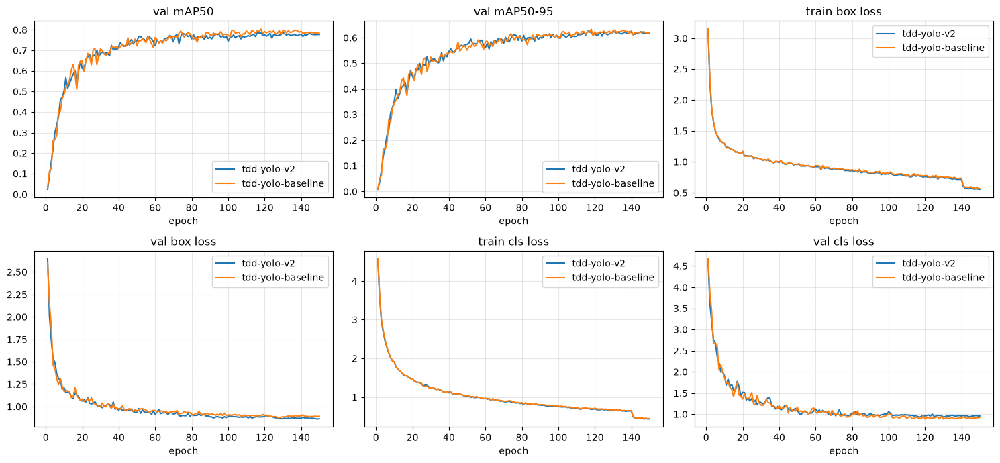

In [9]:
import matplotlib.pyplot as plt
cols = [("metrics/mAP50(B)", "val mAP50"), ("metrics/mAP50-95(B)", "val mAP50-95"),
        ("train/box_loss", "train box loss"), ("val/box_loss", "val box loss"),
        ("train/cls_loss", "train cls loss"), ("val/cls_loss", "val cls loss")]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for name in (NAME_V2, NAME_BASE):
    f = PROJECT / name / "results.csv"
    if not f.exists():
        continue
    r = pd.read_csv(f); r.columns = r.columns.str.strip()
    for ax, (c, t) in zip(axes.flat, cols):
        if c in r:
            ax.plot(r["epoch"], r[c], label=name); ax.set_title(t); ax.set_xlabel("epoch")
for ax in axes.flat:
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(PROJECT / "curves.png", dpi=120); plt.show()

## 10. Sample predictions (test split)

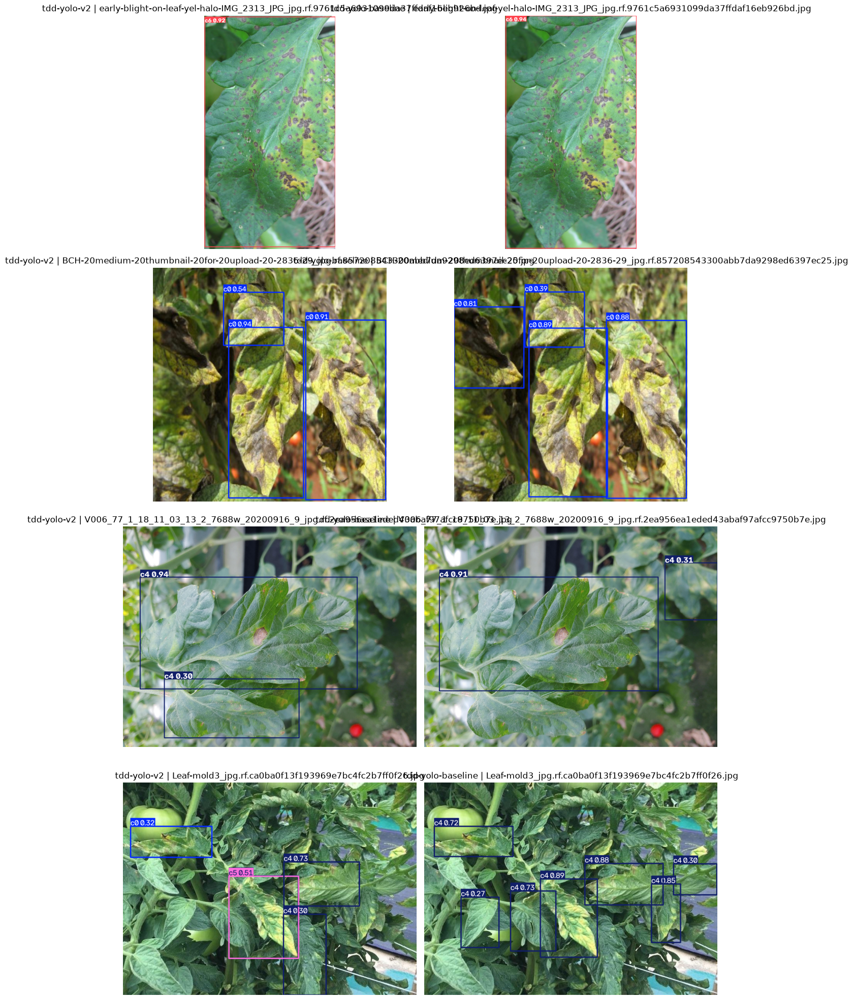

In [10]:
import random
from ultralytics import YOLO
img_dir = Path(D["path"]) / D.get("test", D["val"])
imgs = sorted(p for p in img_dir.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
random.Random(0).shuffle(imgs); imgs = imgs[:4]
models = {n: YOLO(PROJECT / n / "weights" / "best.pt") for n in (NAME_V2, NAME_BASE) if (PROJECT / n / "weights" / "best.pt").exists()}
if imgs and models:
    fig, axes = plt.subplots(len(imgs), len(models), figsize=(6 * len(models), 5 * len(imgs)), squeeze=False)
    for i, im in enumerate(imgs):
        for j, (n, m) in enumerate(models.items()):
            r = m.predict(im, imgsz=S["imgsz"], conf=0.25, iou=0.7, device=S["device"], verbose=False)[0]
            axes[i, j].imshow(r.plot()[..., ::-1]); axes[i, j].set_title(f"{n} | {im.name}"); axes[i, j].axis("off")
    plt.tight_layout(); plt.savefig(PROJECT / "samples.png", dpi=100); plt.show()